# 03 · Líneas base
## Predicción de casos mensuales y alertas de leishmaniosis cutánea en Cajamarca

**Objetivo:** fijar el nivel que cualquier modelo posterior tiene que superar. Según `PIPELINE_PROPUESTO.md` las líneas base son dos reglas sin entrenamiento:

| # | Línea base | Regresión (casos del mes *t*) | Alerta del mes *t* |
|---|---|---|---|
| B1 | Último valor observado | `lag1`: los casos del mes anterior | `lag1` supera el umbral del distrito |
| B2 | Mismo mes del año anterior | `lag12`: los casos de hace 12 meses | `lag12` supera el umbral del distrito |

**Diseño (igual para todos los modelos del proyecto):**
- Unidad: distrito × mes de Cajamarca, con los distritos que acumulan al menos 50 casos (`UMBRAL_CASOS`).
- Partición temporal: entrenamiento hasta 2018, prueba 2019–2024. Nada de esto se ajusta con datos de prueba.
- Solo se usan variables de casos. El clima no entra: no existe en el periodo de prueba (ver `02_eda_clima.ipynb`).
- Métricas: RMSE, MAE y MASE para casos; precisión, recall, F1 y PR-AUC para alertas.

## 1. Inicializar e importar

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score, mean_absolute_error,
                             mean_squared_error, precision_recall_curve, precision_score, recall_score,
                             roc_auc_score)

sys.path.append("../src")
import preprocessing as pp

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12,
                     "figure.figsize": (12, 5)})
pd.options.display.float_format = "{:,.3f}".format

RAW = Path("../data/raw/datos_abiertos_vigilancia_leishmaniosis_2000_2024.csv")
PLOTS = Path("../results/plots")
RESULTS = Path("../results")
PLOTS.mkdir(parents=True, exist_ok=True)

REGION = "CAJAMARCA"
AZUL, NARANJA, GRIS, ROJO = "#2a6f97", "#e07a1f", "#8d99ae", "#9b2226"

## 2. Datos

El panel se construye con `src/preprocessing.py`, filtrando antes los casos a Cajamarca (así lo hace también `integracion_clima.py`). Los rezagos se calculan dentro de cada distrito, y el umbral de alerta (media + 2 desviaciones del distrito) usa solo los meses de entrenamiento.

In [2]:
casos = pp.clean_cases(pp.load_raw(RAW))
casos = casos[casos["departamento"] == REGION]
panel = pp.build_monthly_panel(casos)           # distritos con >= 50 casos acumulados en Cajamarca
train, test = pp.split_train_test(panel)

print(f"Panel: {len(panel):,} filas, {panel['ubigeo'].nunique()} distritos, "
      f"{panel['fecha_mes'].min():%Y-%m} a {panel['fecha_mes'].max():%Y-%m}")
resumen = pd.DataFrame({
    "filas": [len(train), len(test)],
    "meses": [train["fecha_mes"].nunique(), test["fecha_mes"].nunique()],
    "casos por fila (media)": [train["casos"].mean(), test["casos"].mean()],
    "filas con casos > 0 (%)": [(train["casos"] > 0).mean() * 100, (test["casos"] > 0).mean() * 100],
    "alertas": [int(train["alerta"].sum()), int(test["alerta"].sum())],
    "alertas (%)": [train["alerta"].mean() * 100, test["alerta"].mean() * 100],
}, index=["Entrenamiento (2001–2018)", "Prueba (2019–2024)"])
resumen

Panel: 20,160 filas, 70 distritos, 2001-01 a 2024-12


,filas,meses,casos por fila (media),filas con casos > 0 (%),alertas,alertas (%)
Entrenamiento (2001–2018),15120,216,0.750,33.684,744,4.921
Prueba (2019–2024),5040,72,0.413,24.544,183,3.631


In [3]:
# Las dos líneas base solo necesitan lag1 y lag12; se verifica que no haya faltantes
print(panel[["lag1", "lag12", "umbral"]].isna().sum().to_string())
print("Umbral mínimo y máximo entre distritos:", panel["umbral"].min().round(2), "-", panel["umbral"].max().round(2))

lag1      0
lag12     0
umbral    0
Umbral mínimo y máximo entre distritos: 1.1 - 11.49


## 3. Predicciones de las líneas base

Para cada fila (distrito, mes *t*), B1 predice `casos = lag1` y B2 predice `casos = lag12`. Para la alerta, la regla es la misma que define la alerta real pero aplicada al valor pasado: se predice alerta si ese valor supera el umbral del distrito. Como puntaje continuo (para PR-AUC y AUC-ROC) se usa `valor pasado / umbral`.

In [4]:
MODELOS = {"B1 · último mes (lag1)": "lag1", "B2 · mismo mes del año anterior (lag12)": "lag12"}

# MASE: error absoluto medio del modelo dividido por el error absoluto medio del naïve estacional
# en ENTRENAMIENTO (|casos_t - casos_t-12|). Un MASE < 1 mejora al naïve estacional visto en entrenamiento.
ESCALA_MASE = (train["casos"] - train["lag12"]).abs().mean()
print(f"Escala del MASE (MAE del naïve estacional en entrenamiento): {ESCALA_MASE:.3f}")

def metricas_regresion(df, col):
    y, yhat = df["casos"], df[col]
    mae = mean_absolute_error(y, yhat)
    return {"RMSE": np.sqrt(mean_squared_error(y, yhat)), "MAE": mae, "MASE": mae / ESCALA_MASE}

def metricas_alerta(df, col):
    y = df["alerta"]
    pred = (df[col] > df["umbral"]).astype(int)
    puntaje = df[col] / df["umbral"]
    return {"Precisión": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred, zero_division=0),
            "F1": f1_score(y, pred, zero_division=0),
            "PR-AUC": average_precision_score(y, puntaje),
            "AUC-ROC": roc_auc_score(y, puntaje),
            "Alertas predichas": int(pred.sum())}

Escala del MASE (MAE del naïve estacional en entrenamiento): 0.913


## 4. Resultados en regresión

In [5]:
filas = []
for etiqueta, df in [("Entrenamiento", train), ("Prueba", test)]:
    for nombre, col in MODELOS.items():
        filas.append({"Conjunto": etiqueta, "Modelo": nombre, **metricas_regresion(df, col)})
reg = pd.DataFrame(filas)
# MAE relativo a B2 del mismo conjunto: < 1 significa que el modelo mejora al naïve estacional
ref_b2 = reg[reg["Modelo"].str.startswith("B2")].set_index("Conjunto")["MAE"]
reg["MAE / MAE de B2"] = reg["MAE"] / reg["Conjunto"].map(ref_b2)
reg

,Conjunto,Modelo,RMSE,MAE,MASE,MAE / MAE de B2
0,Entrenamiento,B1 · último mes (lag1),1.642,0.816,0.894,0.894
1,Entrenamiento,B2 · mismo mes del año anterior (lag12),1.823,0.913,1.000,1.000
2,Prueba,B1 · último mes (lag1),1.142,0.537,0.588,0.891
3,Prueba,B2 · mismo mes del año anterior (lag12),1.222,0.603,0.660,1.000


In [6]:
# Referencias triviales para dimensionar los errores (no son líneas base del pipeline)
print(f"Casos por fila en prueba: media {test['casos'].mean():.2f}, desviación {test['casos'].std():.2f}, "
      f"máximo {test['casos'].max()}")
refs = {"Media del distrito en entrenamiento": test["ubigeo"].map(train.groupby("ubigeo")["casos"].mean()),
        "Siempre 0": pd.Series(0.0, index=test.index)}
ref_tab = pd.DataFrame([{"Conjunto": "Prueba", "Modelo": "Ref · " + k.lower(),
                         "RMSE": np.sqrt(mean_squared_error(test["casos"], v)),
                         "MAE": mean_absolute_error(test["casos"], v),
                         "MASE": mean_absolute_error(test["casos"], v) / ESCALA_MASE} for k, v in refs.items()])
print(f"Filas de la prueba con 0 casos: {(test['casos'] == 0).mean():.1%}")
ref_tab

Casos por fila en prueba: media 0.41, desviación 0.97, máximo 14
Filas de la prueba con 0 casos: 75.5%


,Conjunto,Modelo,RMSE,MAE,MASE
0,Prueba,Ref · media del distrito en entrenamiento,1.182,0.814,0.892
1,Prueba,Ref · siempre 0,1.054,0.413,0.453


### 4.1 Por año de prueba y por mes del año

In [7]:
por_anio = (test.assign(anio=test["fecha_mes"].dt.year)
            .groupby("anio")
            .apply(lambda g: pd.Series({
                "casos totales": g["casos"].sum(),
                **{f"RMSE {k}": np.sqrt(mean_squared_error(g["casos"], g[c])) for k, c in [("B1", "lag1"), ("B2", "lag12")]},
                **{f"MAE {k}": mean_absolute_error(g["casos"], g[c]) for k, c in [("B1", "lag1"), ("B2", "lag12")]},
            })))
por_anio

,casos totales,RMSE B1,RMSE B2,MAE B1,MAE B2
anio,,,,,
2019,363.000,1.104,1.321,0.596,0.690
2020,328.000,1.017,1.154,0.501,0.613
2021,314.000,1.138,1.152,0.487,0.552
2022,356.000,1.166,1.266,0.504,0.574
2023,317.000,1.154,1.155,0.506,0.573
2024,406.000,1.258,1.271,0.627,0.613


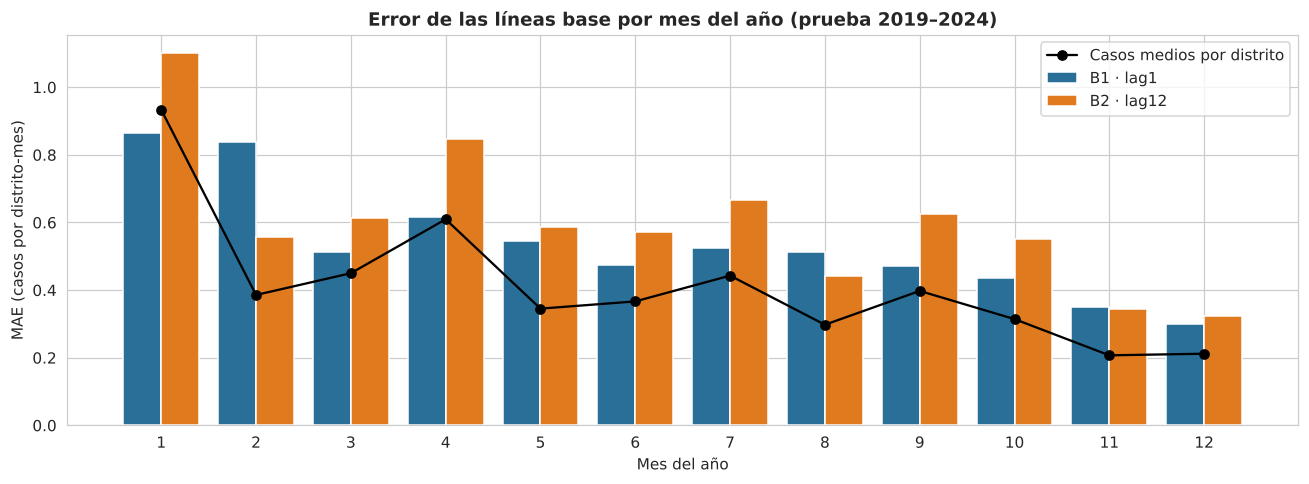

In [8]:
por_mes = (test.assign(mes=test["fecha_mes"].dt.month)
           .groupby("mes")
           .apply(lambda g: pd.Series({"casos medios": g["casos"].mean(),
                                       "MAE B1": mean_absolute_error(g["casos"], g["lag1"]),
                                       "MAE B2": mean_absolute_error(g["casos"], g["lag12"])})))
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(por_mes.index - 0.2, por_mes["MAE B1"], 0.4, color=AZUL, label="B1 · lag1")
ax.bar(por_mes.index + 0.2, por_mes["MAE B2"], 0.4, color=NARANJA, label="B2 · lag12")
ax.plot(por_mes.index, por_mes["casos medios"], color="black", marker="o", lw=1.5, label="Casos medios por distrito")
ax.set_xticks(range(1, 13)); ax.set_xlabel("Mes del año"); ax.set_ylabel("MAE (casos por distrito-mes)")
ax.set_title("Error de las líneas base por mes del año (prueba 2019–2024)"); ax.legend()
plt.tight_layout(); plt.savefig(PLOTS / "baseline_error_por_mes.png", bbox_inches="tight"); plt.show()

### 4.2 Predicho vs. observado

Un RMSE bajo puede esconder un mal ajuste (paper 2). Se revisa el total de Cajamarca mes a mes y el detalle por distrito.

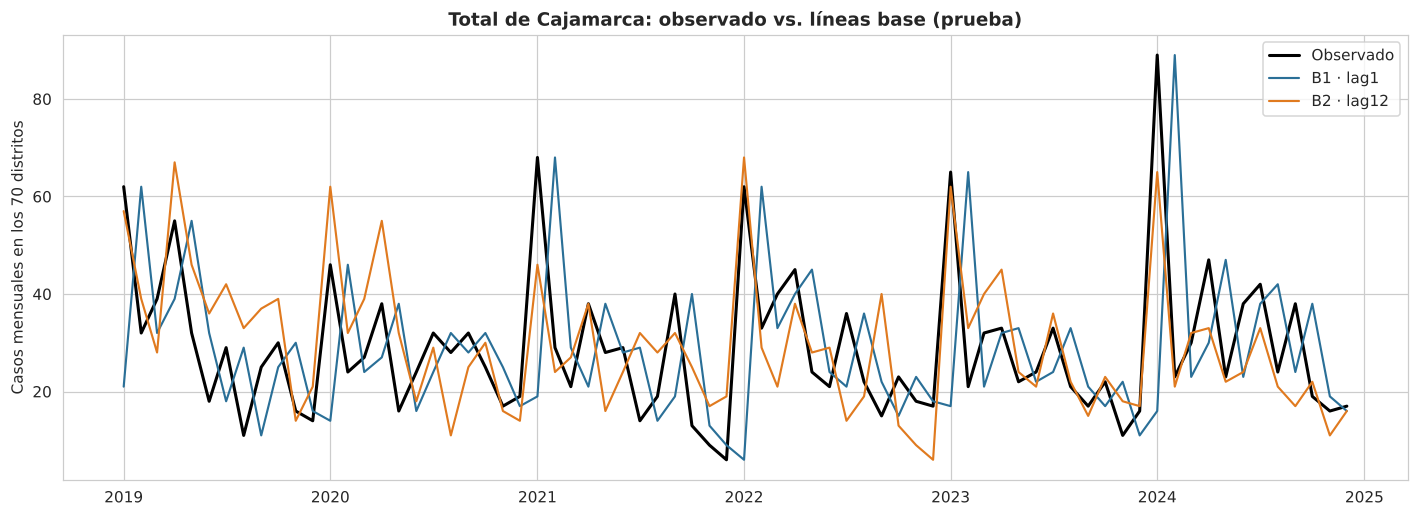

Correlación con el total observado: {'B1': np.float64(-0.073), 'B2': np.float64(0.717)}


In [9]:
tot = test.groupby("fecha_mes")[["casos", "lag1", "lag12"]].sum()
fig, ax = plt.subplots(figsize=(13, 4.8))
ax.plot(tot.index, tot["casos"], color="black", lw=2, label="Observado")
ax.plot(tot.index, tot["lag1"], color=AZUL, lw=1.4, label="B1 · lag1")
ax.plot(tot.index, tot["lag12"], color=NARANJA, lw=1.4, label="B2 · lag12")
ax.set_ylabel("Casos mensuales en los 70 distritos"); ax.set_title("Total de Cajamarca: observado vs. líneas base (prueba)")
ax.legend(); plt.tight_layout(); plt.savefig(PLOTS / "baseline_total_observado_vs_predicho.png", bbox_inches="tight"); plt.show()
print("Correlación con el total observado:",
      {k: round(np.corrcoef(tot["casos"], tot[c])[0, 1], 3) for k, c in [("B1", "lag1"), ("B2", "lag12")]})

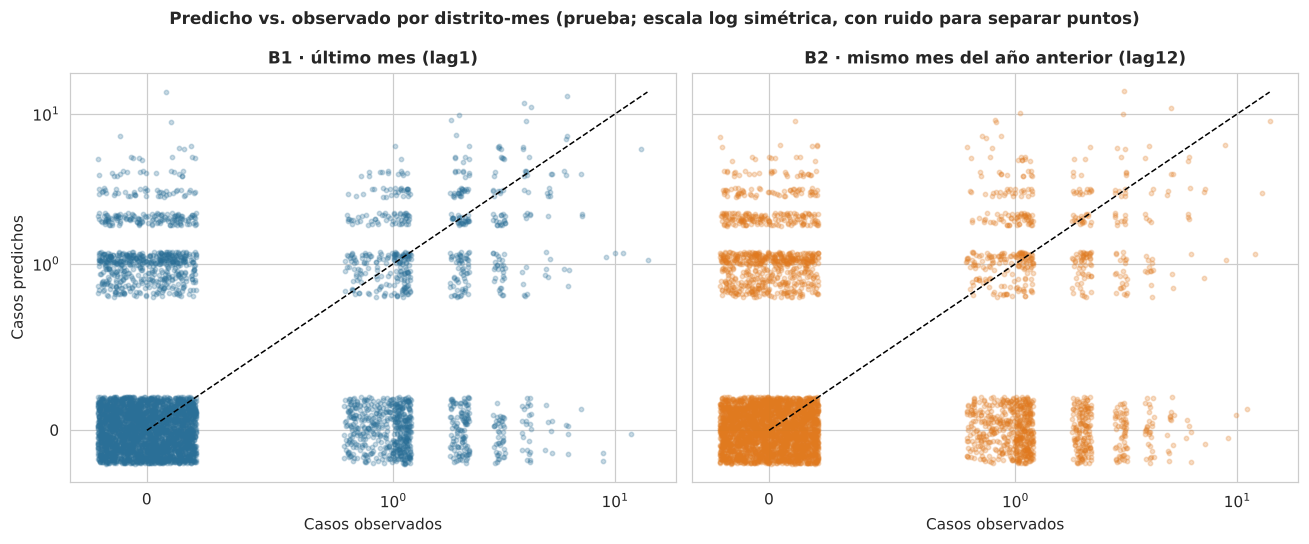

In [10]:
rng = np.random.default_rng(0)
fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for a, (nombre, col), color in zip(ax, MODELOS.items(), [AZUL, NARANJA]):
    a.scatter(test["casos"] + rng.uniform(-0.2, 0.2, len(test)), test[col] + rng.uniform(-0.2, 0.2, len(test)),
              s=8, alpha=0.25, color=color)
    lim = max(test["casos"].max(), test[col].max())
    a.plot([0, lim], [0, lim], color="black", lw=1, ls="--")
    a.set_xscale("symlog", linthresh=1); a.set_yscale("symlog", linthresh=1)
    a.set_title(nombre, fontsize=11); a.set_xlabel("Casos observados")
ax[0].set_ylabel("Casos predichos")
plt.suptitle("Predicho vs. observado por distrito-mes (prueba; escala log simétrica, con ruido para separar puntos)",
             fontweight="bold", fontsize=11)
plt.tight_layout(); plt.savefig(PLOTS / "baseline_predicho_vs_observado.png", bbox_inches="tight"); plt.show()

In [11]:
# ¿Los errores se concentran en pocos distritos?
dist = (test.groupby(["ubigeo", "distrito", "provincia"])
        .apply(lambda g: pd.Series({"casos prueba": g["casos"].sum(),
                                    "MAE B1": mean_absolute_error(g["casos"], g["lag1"]),
                                    "MAE B2": mean_absolute_error(g["casos"], g["lag12"])}))
        .reset_index().sort_values("casos prueba", ascending=False))
print("Distritos con más casos en la prueba:")
display(dist.head(8).drop(columns="ubigeo"))
print(f"Los 10 distritos con más casos concentran {dist['casos prueba'].head(10).sum() / dist['casos prueba'].sum():.0%} "
      f"de los casos de la prueba")

Distritos con más casos en la prueba:


,distrito,provincia,casos prueba,MAE B1,MAE B2
35,SAN LUIS DE LUCMA,CUTERVO,130.000,2.028,2.208
5,CACHACHI,CAJABAMBA,123.000,1.583,1.597
22,CONTUMAZA,CONTUMAZA,111.000,1.750,1.750
3,MAGDALENA,CAJAMARCA,90.000,1.361,1.486
20,TOCMOCHE,CHOTA,83.000,1.167,1.389
48,SALLIQUE,JAEN,66.000,1.000,1.250
15,MIRACOSTA,CHOTA,62.000,1.222,1.431
43,COLASAY,JAEN,60.000,1.042,1.236


Los 10 distritos con más casos concentran 40% de los casos de la prueba


## 5. Resultados en alerta

In [12]:
filas = []
for etiqueta, df in [("Entrenamiento", train), ("Prueba", test)]:
    for nombre, col in MODELOS.items():
        filas.append({"Conjunto": etiqueta, "Modelo": nombre, **metricas_alerta(df, col)})
ale = pd.DataFrame(filas)
print(f"Proporción de alertas reales: entrenamiento {train['alerta'].mean():.2%}, prueba {test['alerta'].mean():.2%} "
      "(es el PR-AUC de un clasificador al azar)")
ale

Proporción de alertas reales: entrenamiento 4.92%, prueba 3.63% (es el PR-AUC de un clasificador al azar)


,Conjunto,Modelo,Precisión,Recall,F1,PR-AUC,AUC-ROC,Alertas predichas
0,Entrenamiento,B1 · último mes (lag1),0.194,0.194,0.194,0.119,0.671,744
1,Entrenamiento,B2 · mismo mes del año anterior (lag12),0.106,0.103,0.105,0.066,0.577,729
2,Prueba,B1 · último mes (lag1),0.213,0.213,0.213,0.153,0.689,183
3,Prueba,B2 · mismo mes del año anterior (lag12),0.123,0.126,0.124,0.090,0.598,187


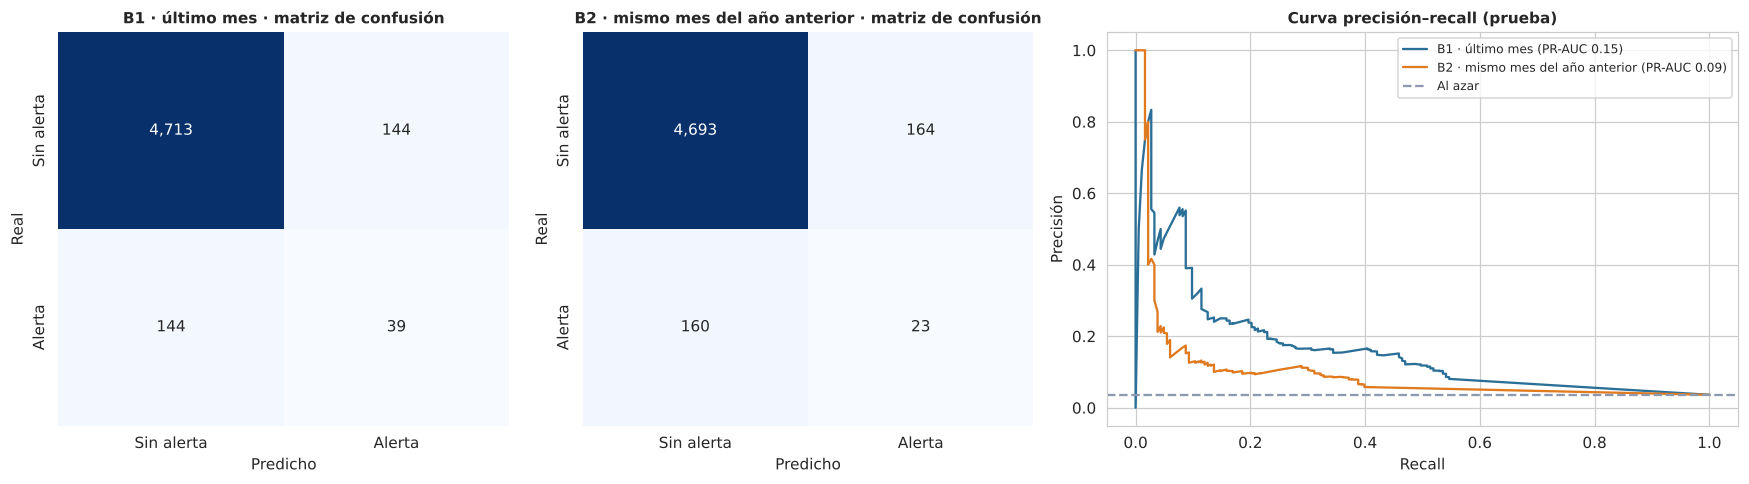

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1, 1, 1.4]})
for a, (nombre, col) in zip(ax[:2], MODELOS.items()):
    cm = confusion_matrix(test["alerta"], (test[col] > test["umbral"]).astype(int))
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=a,
                xticklabels=["Sin alerta", "Alerta"], yticklabels=["Sin alerta", "Alerta"])
    a.set_title(nombre.split(" (")[0] + " · matriz de confusión", fontsize=10)
    a.set_xlabel("Predicho"); a.set_ylabel("Real")
for (nombre, col), color in zip(MODELOS.items(), [AZUL, NARANJA]):
    p, r, _ = precision_recall_curve(test["alerta"], test[col] / test["umbral"])
    ax[2].plot(r, p, color=color, label=f"{nombre.split(' (')[0]} (PR-AUC {average_precision_score(test['alerta'], test[col] / test['umbral']):.2f})")
ax[2].axhline(test["alerta"].mean(), color=GRIS, ls="--", label="Al azar")
ax[2].set_xlabel("Recall"); ax[2].set_ylabel("Precisión"); ax[2].set_title("Curva precisión–recall (prueba)", fontsize=10)
ax[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig(PLOTS / "baseline_alertas.png", bbox_inches="tight"); plt.show()

### 5.1 Qué tan útil es cada alerta

El recall se prioriza porque una alerta no detectada es el error más costoso (papers 1 y 3). Se cuentan las alertas reales que detecta cada regla, las que pierde y cuántas falsas alarmas genera por cada acierto.

In [14]:
filas = []
for nombre, col in MODELOS.items():
    pred = (test[col] > test["umbral"]).astype(int)
    tn, fp, fn, tp = confusion_matrix(test["alerta"], pred).ravel()
    filas.append({"Modelo": nombre, "Alertas reales": tp + fn, "Detectadas": tp, "Perdidas": fn,
                  "Falsas alarmas": fp, "Falsas alarmas por alerta acertada": fp / tp if tp else np.nan})
pd.DataFrame(filas)

,Modelo,Alertas reales,Detectadas,Perdidas,Falsas alarmas,Falsas alarmas por alerta acertada
0,B1 · último mes (lag1),183,39,144,144,3.692
1,B2 · mismo mes del año anterior (lag12),183,23,160,164,7.130


## 6. Guardar los resultados

In [15]:
tabla = pd.concat([reg.assign(Tarea="Regresión"), ref_tab.assign(Tarea="Regresión"), ale.assign(Tarea="Alerta")], ignore_index=True)
tabla = tabla[["Tarea", "Conjunto", "Modelo"] + [c for c in tabla.columns if c not in ("Tarea", "Conjunto", "Modelo")]]
tabla.to_csv(RESULTS / "baseline_metricas.csv", index=False)
print("Guardado:", RESULTS / "baseline_metricas.csv")

Guardado: ../results/baseline_metricas.csv


## 7. Conclusiones

## 7. Conclusiones

**Resultados en la prueba (2019–2024)**

| | B1 · último mes | B2 · mismo mes del año anterior |
|---|---|---|
| RMSE / MAE (casos por distrito-mes) | 1,14 / 0,54 | 1,22 / 0,60 |
| F1 de la alerta | 0,21 | 0,12 |
| PR-AUC de la alerta (al azar: 0,04) | 0,15 | 0,09 |
| Alertas reales detectadas (de 183) | 39 | 23 |
| Falsas alarmas por alerta acertada | 3,7 | 7,1 |

1. **B1 supera a B2 en casi todo.** Reduce el MAE de B2 en 11 %, gana en RMSE los seis años de prueba y en MAE cinco de seis (en 2024 gana B2). En alerta también es mejor, aunque débil: detecta 39 de 183 alertas (21 %) y a cambio genera 144 falsas alarmas.
2. **B2 sí sigue la forma estacional del total.** Al sumar los 70 distritos, B2 se correlaciona 0,72 con el total observado y B1 prácticamente nada (−0,07): B1 repite el mes anterior, así que llega un mes tarde a cada pico, mientras que los picos de enero se repiten cada año. Un modelo que use ambos rezagos (M1 y los siguientes) tiene margen para mejorar a los dos.
3. **Advertencia: predecir siempre 0 gana en RMSE y MAE.** El 75 % de las filas de la prueba tiene cero casos, y la regla "siempre 0" obtiene RMSE 1,05 y MAE 0,41, mejores que B1 (1,14 y 0,54) y B2. Estas dos métricas premian no predecir brotes. Los modelos que sigan deben compararse también con esta referencia y no solo con B1 y B2, y conviene acordar una métrica complementaria que mida si se anticipan los meses con casos (por ejemplo, el error sobre totales por mes o por provincia).
4. **El MASE menor que 1 no significa mejora.** Su escala sale del entrenamiento, donde había casi el doble de casos por fila (0,75 frente a 0,41), por eso B1 y B2 parecen buenos en la prueba (0,59 y 0,66). Para comparar modelos conviene el MAE relativo a B2 de la misma tabla.
5. **Precisión y recall casi iguales.** Cada regla predice entre 183 y 187 alertas, casi las 183 reales, porque copia las alertas de otro mes (B1 las desplaza un mes y B2 un año) y el total apenas cambia; no es un indicador de calidad.
6. **Los errores se concentran en pocos distritos.** Los 10 con más casos en la prueba reúnen el 40 % de los casos y los mayores errores (San Luis de Lucma, Cachachi y Contumazá).

**Meta para los modelos siguientes.** En regresión, bajar de RMSE 1,14 y MAE 0,54 (B1) sin quedar por detrás de "siempre 0" en MAE. En alerta, superar PR-AUC 0,15, F1 0,21 y recall 0,21. Las métricas quedan guardadas en `results/baseline_metricas.csv` para la tabla comparativa final.